# Case study: blind agent EDA on Ames Housing

Most chapters in this book test a single detector on a targeted fixture.
This chapter tests the whole library as an unfamiliar agent actually uses it.

We gave a fresh agent only two inputs: the raw tab-separated Ames Housing
table (Dean De Cock, 2011; 2,930 residential sales across 82 columns,
target `SalePrice` in USD) and `onceover`'s own packaged guide
(`onceover.agent_guide()` and `onceover.capabilities()`), with no access to
the repository's source code or markdown docs. Every call below is reproduced
live from the installed `onceover` package against
`benchmarks/corpus/data/business/ames-housing/data.tsv`.

The walkthrough follows the same five-step loop the agent used:

1. Inspect the frame interpretation with `infer_spec()` before profiling.
2. Run a default `profile(..., target="SalePrice")` and read `to_brief()`.
3. Verify exact invariants and order violations with `verify(df)` and raw Polars.
4. Separate structural absence from missing-at-random fields, then probe
   pricing regimes, non-linear curves, partitioned scatterplots, and model
   failure slices.
5. Check the temporal calendar and distill concrete modeling takeaways.

In [1]:
from html import escape
from pathlib import Path
import base64
import time

import altair as alt
from great_tables import GT
from IPython.display import HTML, display
import numpy as np
import onceover
import polars as pl
import vl_convert as vlc

here = Path.cwd().resolve()
repo = next(
    path for path in (here, *here.parents)
    if (path / "crates/onceover-mines").is_dir()
)


def table(head, rows):
    rows = list(rows)

    def esc_md(val):
        return str(val).replace("|", "\\|")

    def line(row):
        return "| " + " | ".join(esc_md(v) for v in row) + " |"

    data = pl.DataFrame(
        {title: [str(row[i]) for row in rows] for i, title in enumerate(head)}
    )
    display(
        {
            "text/html": GT(data).as_raw_html(),
            "text/markdown": "\n".join(
                [line(head), line(["---"] * len(head)), *(line(r) for r in rows)]
            ),
        },
        raw=True,
    )


def plot(chart, description):
    chart = (
        chart.configure(font="sans-serif", background="white")
        .configure_axis(labelFontSize=12, titleFontSize=12, gridColor="#e9e7df")
        .configure_title(fontSize=13, anchor="start", color="#182a31")
        .configure_view(stroke="#d8dedb")
        .configure_legend(labelFontSize=12, titleFontSize=12)
    )
    png = vlc.vegalite_to_png(chart.to_dict(), scale=2)
    display(
        {"image/png": base64.b64encode(png).decode("ascii")},
        raw=True,
        metadata={"image/png": {"alt": description}},
    )


df = pl.read_csv(
    repo / "benchmarks/corpus/data/business/ames-housing/data.tsv",
    separator="\t",
    null_values=["NA", ""],
)

## 1. Inspect the frame interpretation before profiling

`onceover.infer_spec(df, target="SalePrice")` resolves column roles,
candidate axes, and units without running the statistical passes. On an
unfamiliar 82-column table, checking the spec first takes milliseconds and
catches semantic mismatches before they distort downstream models.

In [2]:
spec = onceover.infer_spec(df, target="SalePrice")

check_cols = ["Order", "PID", "Year Remod/Add", "Pool Area", "3Ssn Porch", "SalePrice"]
table(
    ["Column", "Inferred role", "Source", "Evidence"],
    [
        (c, spec["columns"][c]["role"], spec["columns"][c]["source"], spec["columns"][c]["evidence"])
        for c in check_cols
    ],
)
display(HTML(
    f"<p><strong>Candidate time axis:</strong> "
    f"<code>{escape(str(spec['time_axis']['column']))}</code> "
    f"({escape(spec['time_axis']['evidence'])})</p>"
))

Column,Inferred role,Source,Evidence
Order,row_number,inferred,values run consecutively from 1 in row order (2930 rows)
PID,measure,inferred,numeric column not otherwise classified
Year Remod/Add,measure,inferred,numeric column not otherwise classified
Pool Area,dimension,inferred,14 distinct values
3Ssn Porch,dimension,inferred,31 distinct values
SalePrice,measure,inferred,numeric column not otherwise classified


`infer_spec()` gets `Order` right immediately (consecutive `1..2930` row
number) and keeps `SalePrice` as the declared target. Four adjustments
sharpen the handover before profiling:

- `PID` is a 9-digit assessor parcel identifier, not a continuous measure.
- `Year Remod/Add` is recorded as a low-confidence year axis (`1950..2010`),
  which would route cross-sectional sales through time-series detectors;
  declaring its role as `measure` keeps it available to order-constraint and
  dependence screens.
- `Pool Area` (14 distinct values) and `3Ssn Porch` (31 distinct values) are
  zero-inflated square-footage measures rather than categorical dimensions.
- Declaring `units={"SalePrice": "USD"}` propagates the unit into target
  findings.

## 2. First-pass profile and token-budgeted brief

With that four-line handover, a standard profile runs across all 82 columns
in about one and a half seconds. For an agent operating inside a context
window, `report.to_brief(3_200)` packs the role-grouped schema strip,
headline anomalies, exact invariants, missingness, and target findings into
roughly 800 tokens — each tagged with a short handle (`[f1]`, `[f2]`, …)
for drill-down via `report.finding("f1")`.

In [3]:
hints = {
    "roles": {
        "PID": "identifier",
        "Year Remod/Add": "measure",
        "Pool Area": "measure",
        "3Ssn Porch": "measure",
    },
    "units": {"SalePrice": "USD"},
}

t0 = time.perf_counter()
report = onceover.profile(df, target="SalePrice", hints=hints, budget="standard")
elapsed = time.perf_counter() - t0

display(HTML(
    f"<p><strong>Profiled in {elapsed:.2f} s</strong>: "
    f"{escape(report.overview['headline'])}</p>"
))
print(report.to_brief(3_200))

profile digest: 2930 rows x 82 columns, 100 findings, schema 0.8
Schema: dim: Alley(2,93%null), Bedroom AbvGr(8), Bldg Type(5), Bsmt Cond(5,3%null), Bsmt Exposure(4,3%null), Bsmt Full Bath(4), Bsmt Half Bath(3), Bsmt Qual(5,3%null), BsmtFin Type 1(6,3%null), BsmtFin Type 2(6,3%null), Central Air(2), Condition 1(9), Condition 2(8), Electrical(5), Exter Cond(5), Exter Qual(4), Exterior 1st(16), Exterior 2nd(17), Fence(4,80%null), Fireplace Qu(5,49%null), Fireplaces(5), Foundation(6), Full Bath(5), Functional(8) | num: 1st Flr SF[334..5095,med=1084], 2nd Flr SF[0..2065,med=0], 3Ssn Porch[0..508,med=0], Bsmt Unf SF[0..2336,med=466], BsmtFin SF 1[0..5644,med=370], BsmtFin SF 2[0..1526,med=0], Enclosed Porch[0..1012,med=0], Garage Area[0..1488,med=480] | +50 more cols
What a row is:
Order uniquely identifies rows
time axis — the integer column 'Year Remod/Add' holds plausible years (1950..=2010); recorded as a candidate axis at low confidence, 1950 to 2010 (61 distinct values)
What is wrong:

## 3. Exact invariants, temporal violations, and hidden table ordering

`report.verify(df)` re-evaluates every checkable statement in the report
directly against the raw Polars frame — including uniqueness, exact
arithmetic identities, functional dependencies, outliers, and pairwise
order constraints.

In [4]:
ver = report.verify(df)
summary = (
    ver.group_by(["type", "status"])
    .len()
    .sort(["status", "len"], descending=[True, True])
)
table(
    ["Finding type", "Verification status", "Checks"],
    [(r["type"], r["status"], r["len"]) for r in summary.to_dicts()],
)

print("Exact arithmetic identities:")
for f in report.select(type="arithmetic_identity"):
    print("  -", f["claim"])

print("\nTop temporal and area order-constraint checks:")
for f in report.select(type="order_constraint")[:5]:
    print("  -", f["claim"])

Finding type,Verification status,Checks
order_constraint,ok,36
outcome_contrast,ok,24
extreme_value,ok,18
functional,ok,6
missing_values,ok,6
arithmetic_identity,ok,4
categorical_outlier,ok,4
uniqueness,ok,1
level_contrast,not_checkable,17
value_concentration,not_checkable,12


Exact arithmetic identities:
  - Gr Liv Area = 1st Flr SF + 2nd Flr SF + Low Qual Fin SF within tolerance on all 2930 non-missing rows
  - Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF within tolerance on all 2929 non-missing rows

Top temporal and area order-constraint checks:
  - Bsmt Unf SF <= Gr Liv Area on 2928 of 2929 evaluated rows (1 violations, 0.03%): the worst violation is at row 1013, where Bsmt Unf SF = 1632 against Gr Liv Area = 1474
  - Year Built <= Year Remod/Add on 2929 of 2930 evaluated rows (1 violations, 0.03%): the worst violation is at row 850, where Year Built = 2002 against Year Remod/Add = 2001
  - Garage Yr Blt <= Yr Sold on 2769 of 2771 evaluated rows (2 violations, 0.07%): the worst violation is at row 2260, where Garage Yr Blt = 2207 against Yr Sold = 2007
  - Year Remod/Add <= Yr Sold on 2927 of 2930 evaluated rows (3 violations, 0.10%): the worst violation is at row 2180, where Year Remod/Add = 2009 against Yr Sold = 2007
  - Bsmt Unf SF <= 1

Every checkable finding verifies `ok` against the raw data, including both
three-term area identities (`Gr Liv Area = 1st Flr SF + 2nd Flr SF + Low Qual Fin SF`
on all 2,930 rows; `Total Bsmt SF = BsmtFin SF 1 + BsmtFin SF 2 + Bsmt Unf SF`
on all 2,929 non-null rows) and every `order_constraint` statement.

Following those leads on the raw table immediately exposes four concrete
data-integrity facts:

1. **Future garage year typo.** Row 2260 (`Order = 2261`) records
   `Garage Yr Blt = 2207` on a 2006 home sold in 2007 (clearly `2007`).
2. **Pre-completion sales and remodel inversion.** Row 850 (`Order = 851`)
   has `Year Built = 2002 > Year Remod/Add = 2001`; three `Partial`-condition
   new-construction sales (rows 1702, 2180, 2181) record build or remodel
   years after `Yr Sold`; and `Year Remod/Add` is left-censored at `1950`
   for 361 pre-1950 homes (`100%` of `Year Remod/Add == 1950` rows were built
   in or before 1950).
3. **Standardized townhome floor plan.** `boundary_mass` flags an interior
   spike at `2nd Flr SF = 546` (23 rows, `23×` local baseline) — almost
   entirely `MS SubClass = 160` PUD townhomes in `MeadowV` and `BrDale`.
4. **Hidden table sort order and parcel leakage.** Checking why `Order` and
   `PID` both carry strong nonlinear dependence with `SalePrice` reveals a
   critical modeling hazard: the file is sorted strictly by
   `(Yr Sold DESC, PID ASC)`, and `PID` prefixes encode geographic
   subdivisions.

In [5]:
yr_desc = bool((df["Yr Sold"].diff().drop_nulls() <= 0).all())
within_yr_pid = (
    df.group_by("Yr Sold")
    .agg(
        rows=pl.len(),
        pid_ascending=(pl.col("PID").diff().drop_nulls() >= 0).all(),
        mo_span=pl.format("{}..{}", pl.col("Mo Sold").min(), pl.col("Mo Sold").max()),
        med_price=pl.col("SalePrice").median().cast(pl.Int64),
    )
    .sort("Yr Sold", descending=True)
)
pid4 = (
    df.with_columns(prefix=(pl.col("PID") // 100_000))
    .group_by("prefix")
    .agg(n_nb=pl.col("Neighborhood").n_unique())
)
pure_prefixes = int(pid4.filter(pl.col("n_nb") == 1).height)
remod_1950 = df.filter(pl.col("Year Remod/Add") == 1950)
remod_1950_pre = int(remod_1950.filter(pl.col("Year Built") <= 1950).height)

table(
    ["Yr Sold", "Rows", "PID strictly ascending", "Mo Sold span", "Median SalePrice (USD)"],
    [
        (r["Yr Sold"], r["rows"], r["pid_ascending"], r["mo_span"], f"${r['med_price']:,}")
        for r in within_yr_pid.to_dicts()
    ],
)
display(HTML(
    f"<p><strong>Row order check:</strong> <code>Yr Sold</code> non-increasing across all rows = "
    f"<strong>{yr_desc}</strong>; <strong>{pure_prefixes} of {pid4.height}</strong> 4-digit "
    f"<code>PID</code> prefixes map to a single neighborhood; <strong>{remod_1950_pre} of "
    f"{remod_1950.height}</strong> rows with <code>Year Remod/Add = 1950</code> were built "
    f"in or before 1950.</p>"
))

Yr Sold,Rows,PID strictly ascending,Mo Sold span,Median SalePrice (USD)
2010,341,True,1..7,"$155,000"
2009,648,True,1..12,"$160,850"
2008,622,True,1..12,"$161,000"
2007,694,True,1..12,"$165,125"
2006,625,True,1..12,"$159,500"


A naive row-order train/test split therefore partitions both chronologically
(`2010` at the top, `2006` at the bottom) and geographically (parcel order
within each year), while keeping `PID` or `Order` as numeric predictors
leaks neighborhood identity into `SalePrice`.

## 4. Structural absence vs. missing-at-random fields

Because `"NA"` is loaded as null, 27 columns contain missing values — but
they mean two completely different things. `onceover`'s `missingness`
detector separates deterministic structural absence (where an amenity count
or area is zero) from genuinely missing measurements, and its co-missing
counts immediately reveal the handful of partial-entry corruption rows.

In [6]:
r_miss = onceover.profile(
    df,
    target="SalePrice",
    hints=hints,
    detectors=["missingness"],
    max_findings=60,
)
for f in r_miss.findings[:6]:
    print("  -", f["claim"])

# Raw verification: Lot Frontage missingness by Lot Config vs. structural garage/basement blocks
lf_by_cfg = (
    df.group_by("Lot Config")
    .agg(
        rows=pl.len(),
        missing=pl.col("Lot Frontage").is_null().sum(),
        miss_pct=(pl.col("Lot Frontage").is_null().mean() * 100).round(1),
    )
    .sort("miss_pct", descending=True)
)
g_cols = ["Garage Type", "Garage Yr Blt", "Garage Finish", "Garage Qual", "Garage Cond"]
g_partial = df.filter(
    pl.any_horizontal([pl.col(c).is_null() for c in g_cols])
    & ~pl.all_horizontal([pl.col(c).is_null() for c in g_cols])
)
b_cols = ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
b_partial = df.filter(
    pl.any_horizontal([pl.col(c).is_null() for c in b_cols])
    & ~pl.all_horizontal([pl.col(c).is_null() for c in b_cols])
)

table(
    ["Lot Config", "Rows", "Lot Frontage missing", "Missing rate"],
    [
        (r["Lot Config"], r["rows"], r["missing"], f"{r['miss_pct']:.1f}%")
        for r in lf_by_cfg.to_dicts()
    ],
)
display(HTML(
    f"<p><strong>Partial-block integrity check:</strong> "
    f"<strong>{g_partial.height}</strong> rows have <code>Garage Type = Detchd</code> "
    f"with null year/finish/quality/condition (rows with 157 vs. 159 missing across the 5 garage fields), "
    f"and <strong>{b_partial.height}</strong> rows have partial basement descriptors "
    f"(79 vs. 82/83 missing across the 5 basement fields).</p>"
))

  - Pool QC is missing on 2,917 of 2,930 rows (100%); highest where Pool Area = 0: 100% of 2,917 rows, against 0% elsewhere
  - Fireplace Qu is missing on 1,422 of 2,930 rows (49%); highest where Fireplaces = 0: 100% of 1,422 rows, against 0% elsewhere
  - Lot Frontage is missing on 490 of 2,930 rows (17%); highest where Lot Shape = IR1: 33% of 979 rows, against 8.5% elsewhere
  - Alley is missing on 2,732 of 2,930 rows (93%)
  - Fence is missing on 2,358 of 2,930 rows (80%)
  - Misc Feature is missing on 2,824 of 2,930 rows (96%)


Lot Config,Rows,Lot Frontage missing,Missing rate
CulDSac,180,88,48.9%
FR3,14,4,28.6%
FR2,85,20,23.5%
Corner,511,104,20.4%
Inside,2140,274,12.8%


## 5. Pricing regimes, non-linear curves, and partitioned scatterplots

Targeted passes on `SalePrice` (`regimes`, `target_shapes`) and
`onceover.partition_scagnostics()` explain *why* linear pricing models
underfit the upper tail and why single-floor area looks noisy in aggregate.

- **`regimes`** fits a shallow model tree on the designated target. On Ames
  Housing it splits `SalePrice` into three `Overall Qual` tiers ($\le 5$,
  $6\text{–}7$, $\ge 8$), lifting held-out $R^2$ from `0.755` (one global
  linear model) to `0.817` and revealing convex, multiplicative pricing:
  marginal price per quality point nearly triples from `+$21.2k` in the low
  tier to `+$58.4k` in the luxury tier.
- **`target_shapes`** flags `Year Built`, `Garage Cars`, and `Total Bsmt SF`
  as monotone non-linear curves rather than straight lines.
- **`partition_scagnostics`** tests whether a categorical rule sharpens
  2D scatterplot structure on held-out rows. Both `1st Flr SF × SalePrice`
  and `Total Bsmt SF × SalePrice` are mixtures of two architectural footprints:
  splitting on `House Style = 2Story` lifts held-out Spearman $\rho$ from
  `0.61` pooled to `0.69–0.79` inside the two subgroups ($p = 0.025$).

In [7]:
r_price = onceover.profile(
    df,
    target="SalePrice",
    hints=hints,
    budget="deep",
    detectors=["predictability", "regimes", "target_shapes"],
    max_findings=60,
)

for f in r_price.findings:
    if "SalePrice" in f["claim"] and "regimes" in f["claim"]:
        display(HTML(f"<p><strong>Regimes:</strong> {escape(f['claim'])}</p>"))
        leaves = f["evidence"][0]["metrics"]["leaves"]
        labels = ["Overall Qual <= 5", "5 < Overall Qual <= 7", "Overall Qual > 7"]
        rows = []
        for idx, leaf in enumerate(leaves):
            cond = labels[idx] if idx < len(labels) else " and ".join(
                f"{c['column']} {c['operator']} {c['threshold']:.0f}"
                for c in leaf["conditions"]
            )
            coefs = leaf["coefficients"]
            rows.append((
                cond,
                leaf["n_train"],
                leaf["n_holdout"],
                f"${coefs.get('Gr Liv Area', 0):,.1f} / sf",
                f"${coefs.get('Overall Qual', 0):,.0f}",
                f"${coefs.get('Garage Cars', 0):,.0f}",
            ))
        table(
            ["Regime", "Train", "Holdout", "Gr Liv Area slope", "Overall Qual slope", "Garage Cars slope"],
            rows,
        )

r_shapes = onceover.profile(
    df,
    target="SalePrice",
    hints=hints,
    detectors=["target_shapes"],
)
print("Non-linear target shapes on SalePrice:")
for f in r_shapes.findings:
    print("  -", f["claim"])

Regime,Train,Holdout,Gr Liv Area slope,Overall Qual slope,Garage Cars slope
Overall Qual <= 5,877,230,$31.5 / sf,"$21,166","$12,051"
5 < Overall Qual <= 7,1080,254,$53.8 / sf,"$23,462","$23,365"
Overall Qual > 7,379,109,$47.4 / sf,"$58,352","$50,730"


Non-linear target shapes on SalePrice:
  - Year Built relates to SalePrice as a monotone increasing curve, not a line: a binned curve explains 40.6% of SalePrice's variance, against 31.2% for a straight line (Spearman 0.68)
  - Garage Cars relates to SalePrice as a monotone increasing curve, not a line: a binned curve explains 49.4% of SalePrice's variance, against 42.0% for a straight line (Spearman 0.70)
  - Total Bsmt SF relates to SalePrice as a monotone increasing curve, not a line: a binned curve explains 45.3% of SalePrice's variance, against 40.0% for a straight line (Spearman 0.61)


Pair,Split rule,Pooled ρ,Branch A (held-out),Branch B (held-out),Gain,Adj. p
1st Flr SF vs SalePrice,House Style = 2Story,0.612,2Story: 0.687 (n=407),other: 0.788 (n=1058),+0.205,0.0250
Total Bsmt SF vs SalePrice,House Style = 2Story,0.612,2Story: 0.742 (n=407),other: 0.766 (n=1057),+0.202,0.0250


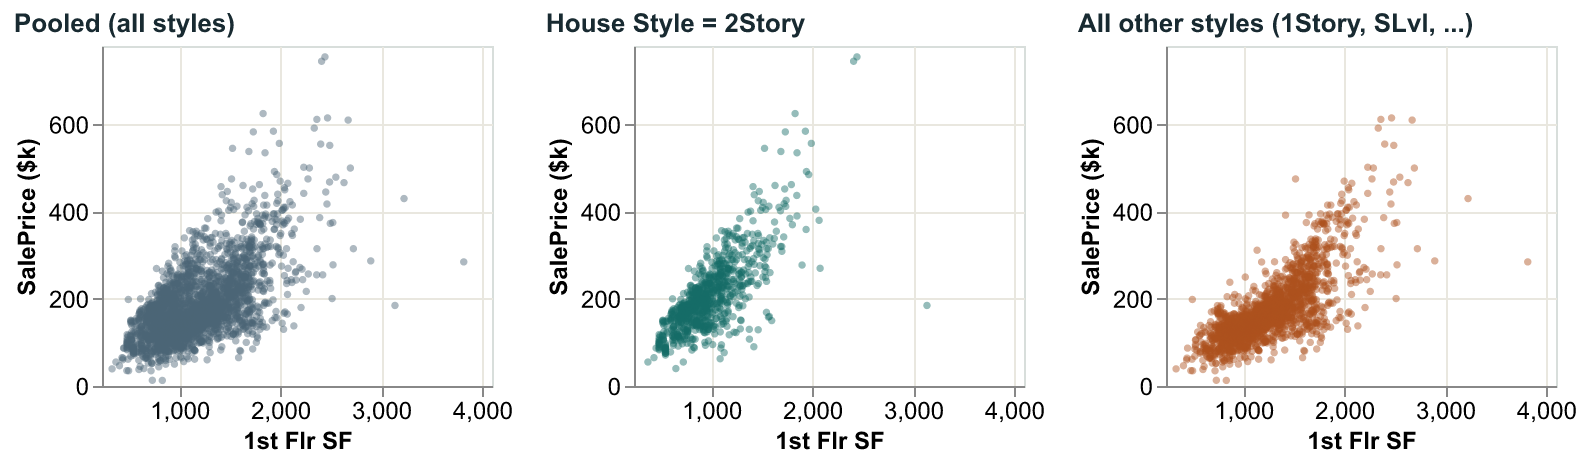

In [8]:
ps = onceover.partition_scagnostics(
    df,
    pairs=[("1st Flr SF", "SalePrice"), ("Total Bsmt SF", "SalePrice")],
    partition_by=["House Style", "Bldg Type", "Sale Condition", "Foundation"],
)

scag_rows = []
for f in ps["findings"]:
    v = f["validation"]
    g0, g1 = v["groups"]
    rule = f"{f['rule']['column']} = {f['rule']['levels'][0]}"
    scag_rows.append((
        f"{f['columns'][0]} vs {f['columns'][1]}",
        rule,
        f"{v['pooled']['rho']:.3f}",
        f"{g0['label']}: {g0['shape']['rho']:.3f} (n={g0['rows']})",
        f"{g1['label']}: {g1['shape']['rho']:.3f} (n={g1['rows']})",
        f"+{v['gain']:.3f}",
        f"{f['adjusted_p_value']:.4f}",
    ))
table(
    ["Pair", "Split rule", "Pooled ρ", "Branch A (held-out)", "Branch B (held-out)", "Gain", "Adj. p"],
    scag_rows,
)

# 3-panel scatterplot for 1st Flr SF vs SalePrice (full data, matching held-out split)
sub = df.select(["1st Flr SF", "SalePrice", "House Style"]).drop_nulls()
x_vals = sub["1st Flr SF"].to_numpy()
y_vals = sub["SalePrice"].to_numpy() / 1_000.0
is_2story = (sub["House Style"] == "2Story").to_numpy()

x_lim = [float(x_vals.min() - 100), float(min(x_vals.max(), 4_000) + 100)]
y_lim = [0.0, float(y_vals.max() + 25)]

panels = []
for title, mask, color in [
    ("Pooled (all styles)", np.ones(len(sub), dtype=bool), "#4a6475"),
    ("House Style = 2Story", is_2story, "#146b66"),
    ("All other styles (1Story, SLvl, ...)", ~is_2story, "#ac501c"),
]:
    keep = mask & (x_vals <= 4_000)
    data = alt.Data(
        values=[{"x": float(a), "y": float(b)} for a, b in zip(x_vals[keep], y_vals[keep])]
    )
    panels.append(
        alt.Chart(data)
        .mark_circle(size=14, opacity=0.45, color=color)
        .encode(
            x=alt.X("x:Q", title="1st Flr SF", scale=alt.Scale(domain=x_lim, nice=False)),
            y=alt.Y("y:Q", title="SalePrice ($k)", scale=alt.Scale(domain=y_lim, nice=False)),
        )
        .properties(title=title, width=195, height=170)
    )

plot(
    alt.hconcat(*panels, spacing=14),
    "Three scatterplots of 1st Flr SF against SalePrice in thousands of USD: pooled cloud, two-story homes, and all other house styles. Splitting out two-story homes separates two tighter linear bands.",
)

The physical intuition is straightforward: for a one-story home, `1st Flr SF`
*is* `Gr Liv Area`; for a `2Story` home, `1st Flr SF` is only about half the
living area, shifting the entire `2Story` cloud upward at any given
first-floor footprint. Pooling them smears two clean pricing bands into one
wider fan.

## 6. Mega-house outliers, model failure slices, and temporal checks

The default report's `model_failures` and `extreme_value` passes point
directly at two structural failure modes in out-of-fold `SalePrice`
predictions:

1. **Five mega-houses (`Gr Liv Area > 4,000` sq ft) split into two opposite
   worlds.** Two `NoRidge` mansions sold for `$745k` and `$755k`, while
   three `Edwards` `Partial` new-construction sales of `4,676–5,642` sq ft
   sold for only `$160k–$184.75k` — the exact outliers Dean De Cock (2011)
   famously advised students to inspect before fitting regressions. Four of
   the five occurred in `2007`, driving the `Yr Sold = 2007 & Gr Liv Area > 2152`
   error slice (`2.7×` overall MAE).
2. **Vintage brick-face underprediction.** `Exterior 1st = BrkFace` (`n = 88`)
   is systematically underpredicted (`+$14.8k` mean residual): conditional on
   `Overall Qual` (especially Qual 6–7), `BrkFace` homes are ~40 years older
   than vinyl peers yet larger and priced `$27k–$44k` higher in median
   `SalePrice`.

Row,Order,Neighborhood,Qual,Gr Liv Area,Bsmt SF,Yr Sold,Sale Cond,SalePrice
1498,1499,Edwards,10,"5,642","6,110",2008,Partial,"$160,000"
2180,2181,Edwards,10,"5,095","5,095",2007,Partial,"$183,850"
2181,2182,Edwards,10,"4,676","3,138",2007,Partial,"$184,750"
1760,1761,NoRidge,10,"4,476","2,396",2007,Abnorml,"$745,000"
1767,1768,NoRidge,10,"4,316","2,444",2007,Normal,"$755,000"


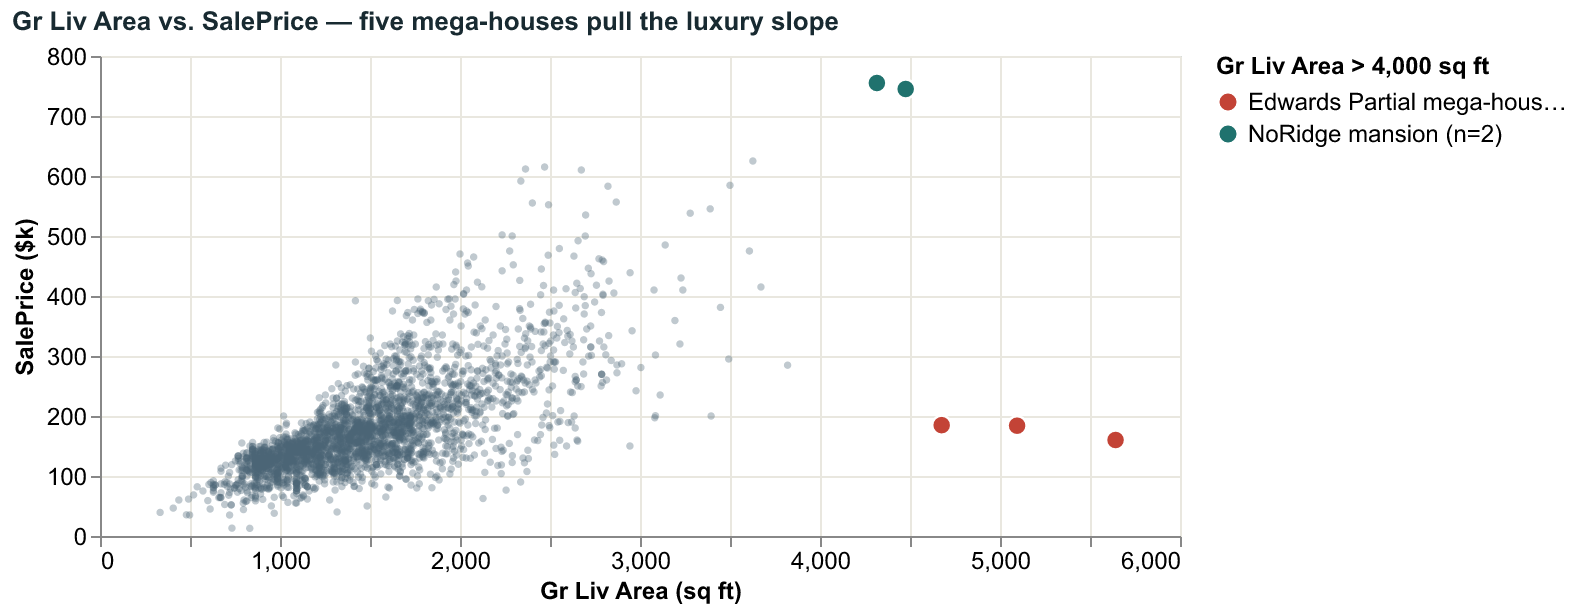

In [9]:
mega = (
    df.with_row_index("row")
    .filter(pl.col("Gr Liv Area") > 4_000)
    .select([
        "row", "Order", "Neighborhood", "Overall Qual",
        "Gr Liv Area", "Total Bsmt SF", "Yr Sold", "Sale Condition", "SalePrice",
    ])
    .sort("Gr Liv Area", descending=True)
)
table(
    ["Row", "Order", "Neighborhood", "Qual", "Gr Liv Area", "Bsmt SF", "Yr Sold", "Sale Cond", "SalePrice"],
    [
        (
            r["row"], r["Order"], r["Neighborhood"], r["Overall Qual"],
            f"{r['Gr Liv Area']:,}", f"{r['Total Bsmt SF']:,}",
            r["Yr Sold"], r["Sale Condition"], f"${r['SalePrice']:,}",
        )
        for r in mega.to_dicts()
    ],
)

# Luxury-tier slope sensitivity with vs. without the 5 mega-houses
lux_all = df.filter(pl.col("Overall Qual") >= 8).select(["Gr Liv Area", "SalePrice"])
lux_trim = lux_all.filter(pl.col("Gr Liv Area") <= 4_000)


def ols_slope(frame):
    x = frame["Gr Liv Area"].to_numpy().astype(float)
    y = frame["SalePrice"].to_numpy().astype(float)
    return float(np.cov(x, y, ddof=0)[0, 1] / np.var(x))


s_all, s_trim = ols_slope(lux_all), ols_slope(lux_trim)

# Scatterplot highlighting the 5 mega-houses
pts = df.select(["Gr Liv Area", "SalePrice", "Sale Condition"]).with_columns(
    group=pl.when((pl.col("Gr Liv Area") > 4_000) & (pl.col("Sale Condition") == "Partial"))
    .then(pl.lit("Edwards Partial mega-house (n=3)"))
    .when(pl.col("Gr Liv Area") > 4_000)
    .then(pl.lit("NoRidge mansion (n=2)"))
    .otherwise(pl.lit("Other sales (n=2,925)"))
)
chart_df = [
    {"gla": int(r["Gr Liv Area"]), "price_k": r["SalePrice"] / 1_000.0, "group": r["group"]}
    for r in pts.to_dicts()
]
base = alt.Chart(alt.Data(values=chart_df))
bg = (
    base.transform_filter(alt.datum.group == "Other sales (n=2,925)")
    .mark_circle(size=14, opacity=0.35, color="#4a6475")
    .encode(
        x=alt.X("gla:Q", title="Gr Liv Area (sq ft)"),
        y=alt.Y("price_k:Q", title="SalePrice ($k)"),
    )
)
fg = (
    base.transform_filter(alt.datum.group != "Other sales (n=2,925)")
    .mark_circle(size=90, opacity=0.95, stroke="white", strokeWidth=1.2)
    .encode(
        x="gla:Q",
        y="price_k:Q",
        color=alt.Color(
            "group:N",
            title="Gr Liv Area > 4,000 sq ft",
            scale=alt.Scale(
                domain=["Edwards Partial mega-house (n=3)", "NoRidge mansion (n=2)"],
                range=["#c0392b", "#146b66"],
            ),
        ),
    )
)
plot(
    (bg + fg).properties(
        title="Gr Liv Area vs. SalePrice — five mega-houses pull the luxury slope",
        width=540,
        height=240,
    ),
    "Scatterplot of Gr Liv Area against SalePrice in thousands of USD highlighting the three low-priced Edwards Partial mega-houses and the two high-priced NoRidge mansions above 4,000 square feet.",
)
display(HTML(
    f"<p><strong>Slope sensitivity (<code>Overall Qual >= 8</code>):</strong> "
    f"<strong>${s_all:,.1f}/sf</strong> across all {lux_all.height} luxury homes vs. "
    f"<strong>${s_trim:,.1f}/sf</strong> after excluding the 5 homes above 4,000 sq ft "
    f"(a <strong>+{(s_trim / s_all - 1) * 100:.1f}%</strong> shift).</p>"
))

Finally, assembling a monthly `Sale Date = date(Yr Sold, Mo Sold, 1)` and
running the temporal passes (`date_gaps`, `series`, `distribution_change`)
confirms two subtleties that are easy to misread without verification:

- **Complete 55-month calendar, right-truncated in 2010.** Every month from
  `2006-01` through `2010-07` is present (`0` gaps), with `2010` ending
  after July (`341` rows vs. `622–694` in full years). Sales volume is 4×
  higher in June–July than in December–February, while median `SalePrice`
  stays flat (`$155k–$165k`) through the 2008 housing downturn.
- **Right-censoring artifact in `distribution_change`.** Including
  `Year Built` / `Year Remod/Add` / `Garage Yr Blt` triggers six apparent
  multivariate splits along `Sale Date` simply because a home built in 2009
  cannot be sold in 2007. Dropping those three build-year columns collapses
  six splits to a single weak split at `2006-07-01`.

In [10]:
df_t = df.with_columns(pl.date(pl.col("Yr Sold"), pl.col("Mo Sold"), 1).alias("Sale Date"))
t_hints = {**hints, "time": "Sale Date"}

r_time_all = onceover.profile(
    df_t,
    target="SalePrice",
    hints=t_hints,
    detectors=["date_gaps", "distribution_change"],
)
r_time_noyr = onceover.profile(
    df_t.drop(["Year Built", "Year Remod/Add", "Garage Yr Blt"]),
    target="SalePrice",
    hints={
        "roles": {"PID": "identifier", "Pool Area": "measure", "3Ssn Porch": "measure"},
        "units": {"SalePrice": "USD"},
        "time": "Sale Date",
    },
    detectors=["date_gaps", "distribution_change"],
)

print("date_gaps coverage:", r_time_all.coverage["date_gaps"]["detail"])
print(
    f"distribution_change splits: {len(r_time_all.select(type='joint_distribution_change'))} "
    f"with build-year columns vs. "
    f"{len(r_time_noyr.select(type='joint_distribution_change'))} after dropping build-year columns"
)

date_gaps coverage: 1 temporal columns, 0 gap events
distribution_change splits: 6 with build-year columns vs. 1 after dropping build-year columns


## 7. Summary and modeling takeaways

On an unfamiliar 82-column table (`3,321` column pairs), `onceover` ran a
full first-pass profile in **1.5 s** (`budget="standard"`) and **2.0 s**
(`budget="deep"`), with standalone `partition_scagnostics` taking
**0.03 s**. Instead of writing dozens of exploratory scripts by hand, the
agent spent its turns verifying specific leads and translating them into
five concrete modeling decisions:

1. **Split carefully and drop `Order` / `PID`.** Row order is strictly
   `(Yr Sold DESC, PID ASC)` and 36 of 64 four-digit `PID` prefixes map to
   a single neighborhood, so naive row-order splits partition both time and
   geography while numeric `PID` leaks location.
2. **Separate structural absence from MAR missingness.** Recode structural
   `NA`s (`Pool QC`, `Fireplace Qu`, garage and basement blocks) as
   explicit absence categories, fix the handful of partial-block rows, and
   impute `Lot Frontage` conditionally on `Lot Config` / `Lot Shape`.
3. **Clean verified data-entry artifacts.** Correct `Garage Yr Blt = 2207`
   (row 2260), account for `Year Remod/Add` left-censoring at `1950` (361
   pre-1950 homes), and inspect the three `Edwards` `Partial` mega-houses
   (`Gr Liv Area > 4,000` sq ft) that pull the luxury-tier slope down by
   22%.
4. **Model convex pricing and architectural footprints.** Log-transforming
   `SalePrice` or interacting `Overall Qual` with area captures the 3-tier
   regime jump (`$21.2k` → `$58.4k` per quality point), while interacting
   `House Style = 2Story` with `1st Flr SF` / `Total Bsmt SF` separates the
   two footprint clouds.
5. **Check temporal censoring before claiming drift.** Sales span 55
   consecutive months (`2006-01` through `2010-07`, right-truncated after
   July 2010) with flat median prices across 2006–2010; apparent
   multivariate breaks along `Sale Date` largely vanish once build-year
   columns are excluded.